# 05 · Derangements, hybridisation, and the rank-2 structure behind the closed form

Tracing the cavity field out of the Langevin equations leaves each motion driven by every other
one through *hybridisation functions* $R_{j_n k_m}(\omega)$. This notebook looks at that structure
three ways: as a matrix to invert numerically; as an exact, finite power series over the
derangements of the motions, which shows the hybridisation order by order but costs factorially;
and as a rank-2 update of a diagonal matrix, which is why a closed form exists at all.

**Runtime:** about 30 s. **Background:** [Calculation methods](../../docs/concepts/calculation_methods.md),
methods (4), (5) and (6)-(7), and the code pathway notes on `hybridisation_matrix` there.

In [1]:
import os
os.environ.setdefault('TQDM_DISABLE', '1')

import contextlib
import io
import math
import time

import numpy as np
import matplotlib.pyplot as plt

from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz, degrees
from levisim.multiphysics.enums import QuantumLinearTheoryMethod
from levisim.multiphysics.hybridisation import generate_determinant_and_adjugate_by_order, generate_subscripts_and_labels
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.utils.shelf import DEFAULT_cavity_kwargs, DEFAULT_gas_kwargs, PHASE_DEPENDENT_toy_params

set_plt_rcParams_to_xmgrace_style()
LAM = QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
NUMERICAL = QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
POWER_SERIES = QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
ANALYTIC = QuantumLinearTheoryMethod.ANALYTIC_CAVITY_OUTPUT

def quietly(function, *args):
    # call a levisim spectrum function without its progress messages
    with contextlib.redirect_stdout(io.StringIO()):
        return function(*args)

## 1. Hybridisation functions

Eliminate the light: each position is its own one-dimensional solution plus the response to every
other position,

$$
\hat q_{j_n}(\omega) = \hat q_{j_n,\text{1D}}(\omega) + \sum_{k_m \neq j_n} R_{j_n k_m}(\omega)\,\hat q_{k_m}(\omega)
\quad\Longrightarrow\quad
\mathbf D\,\hat{\mathbf q} = \hat{\mathbf q}_\text{1D}, \qquad \mathbf D = \mathbf I - \mathbf R .
$$

$\mathbf D$ is the *derangement matrix* (`mtrap.derangement_matrix(ω)`): ones on the diagonal, $-R_{j_n k_m}$
off it. Here is $|R_{j_n k_m}|$ for eight particles moving along $x$, with frequencies evenly spaced
over 280-320 kHz and tweezer phases stepping by 20°, at a frequency between two resonances:

ω0/2π = 297.3 kHz
x1: Ω/2π = 280.00 kHz, one-dimensional resonance at 273.69 kHz
x2: Ω/2π = 285.71 kHz, one-dimensional resonance at 279.43 kHz
x3: Ω/2π = 291.43 kHz, one-dimensional resonance at 285.18 kHz
x4: Ω/2π = 297.14 kHz, one-dimensional resonance at 290.93 kHz
x5: Ω/2π = 302.86 kHz, one-dimensional resonance at 296.68 kHz
x6: Ω/2π = 308.57 kHz, one-dimensional resonance at 302.44 kHz
x7: Ω/2π = 314.29 kHz, one-dimensional resonance at 308.21 kHz
x8: Ω/2π = 320.00 kHz, one-dimensional resonance at 313.99 kHz


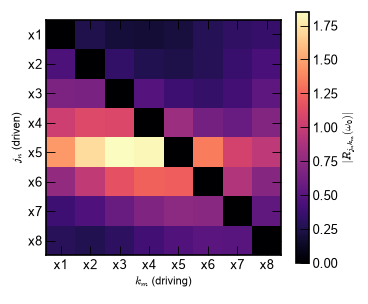

In [2]:
toy = dict(Ω_model='equal spacing', Ω_mid=300 * kHz, Ω_span=40 * kHz, toy_gx=-40 * kHz,
           φn_dict={n: (n - 1) * 20 * degrees for n in range(1, 9)})
eight = MultiTrap(num_traps=8, Cartesian_axes_per_trap=1, toy_params=toy,
                  gas_kwargs=DEFAULT_gas_kwargs, cavity_kwargs=DEFAULT_cavity_kwargs, ω_range=np.array([0.0]))
ω0 = 297.3 * kHz
D = eight.derangement_matrix(ω0)
R = np.eye(eight.num_dimensions) - D

fig, ax = plt.subplots(figsize=(4.6, 3.8))
image = ax.imshow(np.abs(R), cmap='magma')
ax.set_xticks(range(8), eight.labels)
ax.set_yticks(range(8), eight.labels)
ax.set_xlabel('$k_m$ (driving)')
ax.set_ylabel('$j_n$ (driven)')
fig.colorbar(image, ax=ax, label=r'$|R_{j_n k_m}(\omega_0)|$')
fig.tight_layout()
# the one-dimensional resonance of each motion (in the cavity, without the others) is the peak of |μ_j/M_j|
grid = np.linspace(260, 330, 70001) * kHz
print(f'ω0/2π = {ω0 / kHz} kHz')
for label, dim in eight.dimensions.items():
    resonance = grid[np.argmax(np.abs(dim.μm(grid) / dim.M(grid)))]
    print(f'{label}: Ω/2π = {dim.Ω / kHz:6.2f} kHz, one-dimensional resonance at {resonance / kHz:6.2f} kHz')

The brightest row is $x_5$. Its bare frequency is 302.9 kHz, but the optical spring (about
$-6$ kHz at this coupling) puts its one-dimensional resonance at 296.7 kHz, next to $\omega_0$; a
motion near its resonance responds strongly to everything the cavity feeds it. The rows share a
common pattern, which section 5 makes exact.

## 2. The inverse as a sum over derangements

$\hat{\mathbf q} = \mathbf D^{-1}\hat{\mathbf q}_\text{1D}$ with $\mathbf D^{-1} = \operatorname{adj}\mathbf D/\det\mathbf D$. Expand the
determinant over permutations: because the diagonal of $\mathbf D$ is 1, each term is a product of
$R$'s around the cycles of the elements the permutation moves, i.e. over a *derangement* of a
subset. The order of a term is its number of $R$ factors. For $n$ motions there are
$\binom{n}{k}\,!k$ terms of order $k$ ($!k$ = derangements of $k$ objects), $n!$ in total; each adjugate
entry is a similar sum with $(n-1)!$ terms. `levisim.multiphysics.hybridisation` generates them
symbolically:

In [3]:
def subfactorial(k):
    return round(math.factorial(k) / math.e) if k > 0 else 1

print(' n   terms of det(D) up to each order (cumulative)        total    n!   check')
for n in range(2, 8):
    _, labels = generate_subscripts_and_labels(n, 1)
    with contextlib.redirect_stdout(io.StringIO()):
        determinant, adjugate = generate_determinant_and_adjugate_by_order(n=n, labels=labels, max_order=n)
    counts = [len(determinant[order]) for order in sorted(determinant)]
    formula = np.cumsum([math.comb(n, k) * subfactorial(k) for k in range(n + 1)])[1:]
    print(f'{n:2d}   {str(counts):50s} {counts[-1]:6d} {math.factorial(n):6d}   {counts == list(formula)}')

 n   terms of det(D) up to each order (cumulative)        total    n!   check
 2   [1, 2]                                                  2      2   True
 3   [1, 4, 6]                                               6      6   True
 4   [1, 7, 15, 24]                                         24     24   True
 5   [1, 11, 31, 76, 120]                                  120    120   True
 6   [1, 16, 56, 191, 455, 720]                            720    720   True
 7   [1, 22, 92, 407, 1331, 3186, 5040]                   5040   5040   True


The first entry is the single order-1 "term", 1 (the identity permutation); order 2 adds the
$\binom n2$ two-cycles $R_{jk}R_{kj}$, and so on. Evaluated with every term, the series is exact. Check
it at $\omega_0$ for the stable `PHASE_DEPENDENT` toy system of two particles in $x$ and $y$, whose
series is shipped pre-generated (`load_in_power_series=True`):

In [4]:
system = MultiTrap(num_traps=2, Cartesian_axes_per_trap=2, toy_params=PHASE_DEPENDENT_toy_params,
                   gas_kwargs=DEFAULT_gas_kwargs, cavity_kwargs=DEFAULT_cavity_kwargs,
                   ω_range=np.linspace(285, 320, 400) * kHz, load_in_power_series=True)
ω1 = 301.2 * kHz
D_system = system.derangement_matrix(ω1)
det_series = system.deranged_determinant(ω1)
adj_series = np.array([[system.deranged_adjugate_matrix_entry(a + b, ω1) for b in system.labels] for a in system.labels])
print(f'det(D): power series {det_series:.12f}')
print(f'        numpy        {np.linalg.det(D_system):.12f}')
print(f'adj(D)/det(D) vs inverse: max relative difference {np.max(np.abs(adj_series / det_series - np.linalg.inv(D_system))) / np.max(np.abs(np.linalg.inv(D_system))):.1e}')

det(D): power series -0.017344360809+0.022802039284j
        numpy        -0.017344360809+0.022802039284j
adj(D)/det(D) vs inverse: max relative difference 1.4e-14


## 3. Truncating the series

`evaluation_order` keeps only the terms up to a given order. That shows how much of a spectrum is
already there with pairwise hybridisation (order 2), three-body loops (order 3), and so on:

order 1: relative error median 1.8e+00, max 8.9e+01; smallest value 0.602 (shot noise = 1)
order 2: relative error median 7.9e-01, max 2.7e+00; smallest value 1.372 (shot noise = 1)
order 3: relative error median 1.8e-01, max 1.0e+00; smallest value 0.984 (shot noise = 1)
order 4: relative error median 6.7e-16, max 8.1e-14; smallest value 1.288 (shot noise = 1)


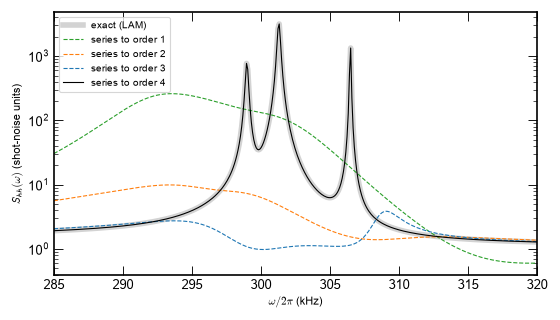

In [5]:
f = system.ω_range / kHz
exact = quietly(system.homodyne_spectrum, LAM)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(f, exact, color='lightgrey', lw=5, label='exact (LAM)')
for order, colour in zip((1, 2, 3, 4), ('tab:green', 'tab:orange', 'tab:blue', 'k')):
    system.evaluation_order = order
    truncated = quietly(system.homodyne_spectrum, POWER_SERIES)
    relative = np.abs(truncated / exact - 1)
    ax.semilogy(f, truncated, color=colour, lw=1, ls='-' if order == 4 else '--', label=f'series to order {order}')
    print(f'order {order}: relative error median {np.median(relative):.1e}, max {np.max(relative):.1e};'
          f' smallest value {truncated.min():.3f} (shot noise = 1)')
system.evaluation_order = system.num_dimensions
ax.set_xlim(f[0], f[-1])
ax.set_xlabel(r'$\omega / 2\pi$ (kHz)')
ax.set_ylabel(r'$S_{hh}(\omega)$ (shot-noise units)')
ax.legend(fontsize=9, loc='upper left')
fig.tight_layout()

Low orders are not an approximation scheme here. Near the hybridised resonances some $|R_{jk}|$ are
of order 1, so the truncated series is wrong by factors, and at order 1 it even dips below the
shot-noise level, which no physical spectrum can. Only the complete series (order $n = 4$) is
right, to $10^{-13}$. What the series offers is *structure*: each term is a named loop of
hybridisation, and its size at each frequency says which loops matter.

## 4. The cost of the series

Time the full series against the numerical inverse of $\mathbf D$, LAM and the closed form, for $n$
particles moving along $x$:

n                  power series   numerical hybridisation                       LAM               closed form
1                         0.063                     0.066                     0.048                     0.125
2                         0.195                     0.112                     0.049                     0.127
3                         3.634                     0.737                     0.051                     0.213
4                        11.182                     0.734                     0.109                     0.185
5                        31.327                     0.630                     0.071                     0.239
6                        78.594                     0.545                     0.075                     0.221
7                       302.243                     0.629                     0.370                     0.259


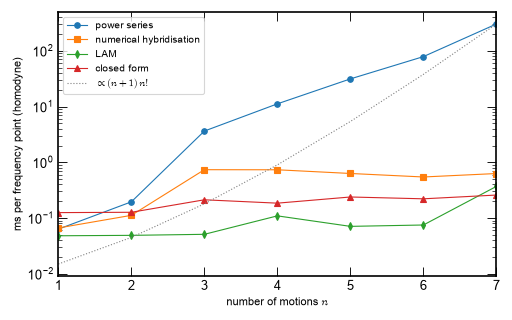

In [6]:
sizes = range(1, 8)
costs = {name: [] for name in ('power series', 'numerical hybridisation', 'LAM', 'closed form')}
methods = {'power series': POWER_SERIES, 'numerical hybridisation': NUMERICAL, 'LAM': LAM, 'closed form': ANALYTIC}
grid = np.linspace(280, 320, 12) * kHz
repeats = 3   # keep the fastest of a few repeats: timings on a busy machine only ever err upwards
for n in sizes:
    with contextlib.redirect_stdout(io.StringIO()):
        mt = MultiTrap(num_traps=n, Cartesian_axes_per_trap=1, ω_range=grid,
                       toy_params=dict(Ω_model='equal spacing', Ω_mid=300 * kHz, Ω_span=40 * kHz, toy_gx=-40 * kHz),
                       gas_kwargs=DEFAULT_gas_kwargs, cavity_kwargs=DEFAULT_cavity_kwargs, generate_power_series=True)
    for name, method in methods.items():
        seconds = []
        for _ in range(1 if (name == 'power series' and n == 7) else repeats):
            start = time.perf_counter()
            quietly(mt.homodyne_spectrum, method)
            seconds.append(time.perf_counter() - start)
        costs[name].append(1e3 * min(seconds) / len(grid))

fig, ax = plt.subplots(figsize=(6.4, 4))
for (name, values), marker in zip(costs.items(), 'osd^'):
    ax.semilogy(list(sizes), values, marker + '-', ms=5, label=name)
terms = np.array([math.factorial(n) * (1 + n) for n in sizes], dtype=float)   # det + one adjugate row
ax.semilogy(list(sizes), costs['power series'][-1] * terms / terms[-1], ':', color='grey', label=r'$\propto (n+1)\,n!$')
ax.set_xlim(1, 7)
ax.set_xlabel('number of motions $n$')
ax.set_ylabel('ms per frequency point (homodyne)')
ax.legend(fontsize=9, loc='upper left')
fig.tight_layout()
print('n      ' + '  '.join(f'{name:>24s}' for name in costs))
for ii, n in enumerate(sizes):
    print(f'{n:<6d} ' + '  '.join(f'{values[ii]:24.3f}' for values in costs.values()))

The series is never the fast route: it matches the numerical inverse only for a single motion,
then grows roughly like the number of its terms, so by $n = 7$ (5040 determinant terms) it costs
two to three orders of magnitude more per point than inverting $\mathbf D$. The numerical inverse in turn costs more
than LAM here, because building $\mathbf D$ means $n^2 - n$ Python-level evaluations of $R_{jk}$, while
LAM inverts its larger $(2n+2)$-square matrix in one compiled call. (Absolute timings depend on the
machine and its load.) Above $n = 9$ levisim does not generate the series at all.

## 5. Why a closed form exists: $\mathbf R$ has rank 2 (plus a diagonal)

All the cavity-mediated coupling goes through *one* optical mode, i.e. through two operators,
$\hat a$ and $\hat a^\dagger$. Writing $\mu_j = \chi_j(\omega) - \chi_j^*(-\omega)$ and $M_j$ for each motion's
one-dimensional normalisation (`Dimension.μm`, `Dimension.M`), the off-diagonal elements are

$$
R_{jk}(\omega) = \frac{i\mu_j}{M_j}\,C_{jk}, \qquad
\mathbf C = i\chi_\text{c}(\omega)\,\mathbf G^*\mathbf G^\top - i\chi_\text{c}^*(-\omega)\,\mathbf G\,\mathbf G^\dagger,
$$

so $\mathbf R$ is a diagonal matrix times a rank-2 matrix, with the diagonal removed. Check it on the
eight-particle system of section 1:

In [7]:
G = eight.G_array
χc, χc_conj_minus = eight.cavity.χC(ω0), np.conj(eight.cavity.χC(-ω0))
C = 1j * χc * np.outer(np.conj(G), G) - 1j * χc_conj_minus * np.outer(G, np.conj(G))
μ = np.array([dim.μm(ω0) for dim in eight.dimensions.values()])
M = np.array([dim.M(ω0) for dim in eight.dimensions.values()])
rank_2 = 1j * (μ / M)[:, np.newaxis] * C

off_diagonal = ~np.eye(8, dtype=bool)
print(f'off-diagonal R vs i(μ/M)C: max relative difference {np.max(np.abs(rank_2 - R)[off_diagonal]) / np.max(np.abs(R)):.1e}')
singular_values = np.linalg.svd(R + np.diag(np.diag(rank_2)), compute_uv=False)
print('singular values of R with its diagonal restored, normalised:', np.array2string(singular_values / singular_values[0], precision=1))

off-diagonal R vs i(μ/M)C: max relative difference 1.4e-16
singular values of R with its diagonal restored, normalised: [1.0e+00 2.1e-01 1.9e-16 5.6e-17 3.9e-17 2.1e-17 8.2e-18 1.9e-18]


Two singular values are non-zero; the other six are rounding error. A rank-2 update of a diagonal
matrix is inverted by the Woodbury identity at the cost of a 2×2 inverse, which is the closed form
of methods (6) and (7): `mtrap.analytic_hybridisation_matrix(ω)` returns $\mathbf D^{-1}$ without inverting
any $n\times n$ matrix (with direct $x$-$y$ couplings off the node it needs one small inverse per particle
as well). Against `np.linalg.inv`:

In [8]:
closed_form = eight.analytic_hybridisation_matrix(ω0)
numerical = np.linalg.inv(D)
print(f'D⁻¹ closed form vs numerical inverse: max relative difference {np.max(np.abs(closed_form - numerical)) / np.max(np.abs(numerical)):.1e}')

D⁻¹ closed form vs numerical inverse: max relative difference 7.6e-16


The same structure explains what the cavity does physically: it couples to the motions only through
the two collective combinations $\mathbf G^\top\hat{\mathbf q}$ and $\mathbf G^\dagger\hat{\mathbf q}$ (one combination when all
tweezer phases are equal), so for many particles most collective modes are *dark* to it. The
showcase notebook, [`many_particles_one_cavity`](../showcase/many_particles_one_cavity.ipynb), follows
that to a hundred particles.